 # Collab

In [3]:
import os

print(os.listdir("/content"))

['.config', 'data (1).xlsx', 'sample_data']


## EDA — Statistiques descriptives

In [21]:
df[["Quantity","UnitPrice"]].describe()

,Quantity,UnitPrice
count,392692.000000,392692.000000
mean,13.119702,3.125914
std,180.492832,22.241836
min,1.000000,0.001000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,8142.750000


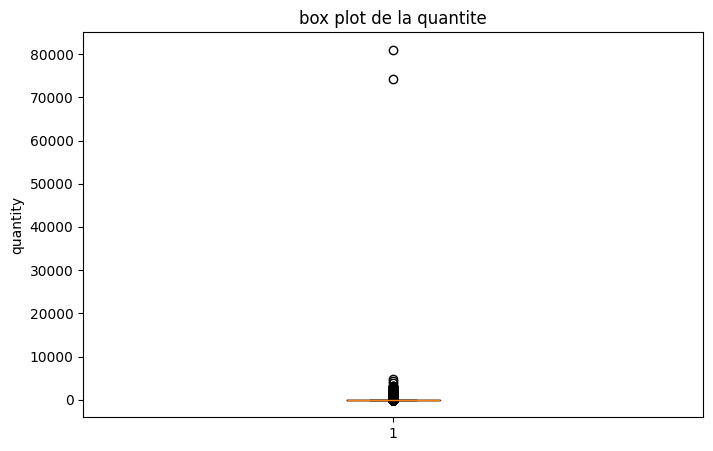

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.boxplot(df["Quantity"])
plt.title("box plot de la quantite")
plt.ylabel("quantity")

plt.show()

In [23]:
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)

IQR = Q3 - Q1

borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Borne inférieure =", borne_inf)
print("Borne supérieure =", borne_sup)

Q1 = 2.0
Q3 = 12.0
IQR = 10.0
Borne inférieure = -13.0
Borne supérieure = 27.0


In [24]:
outliers_quantity =df[
    (df["Quantity"] < borne_inf) |
    (df["Quantity"] > borne_sup)
]


print("nombre des outliers",len(outliers_quantity))

nombre des outliers 25616


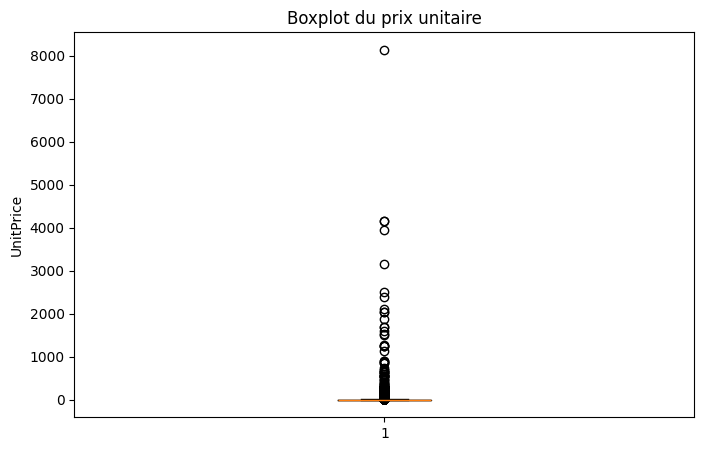

In [25]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["UnitPrice"])

plt.title("Boxplot du prix unitaire")
plt.ylabel("UnitPrice")

plt.show()

In [26]:
Q3 = df["UnitPrice"].quantile(0.75)
Q1 = df["UnitPrice"].quantile(0.25)

IQR = Q3 - Q1
lower =Q1 -1.5 * IQR
Upper = Q3 + 1.5 * IQR

print(Q3)
print(Q1)
print(IQR)
print(lower)
print(Upper)


3.75
1.25
2.5
-2.5
7.5


In [42]:
outliers_price = df[(df["UnitPrice"] < lower) |(df["UnitPrice"]> Upper)]
print(len(outliers_price))

34112


In [36]:
print((df["Quantity"]> 10000).sum())
print((df["UnitPrice"]> 1000).sum())

2
21


In [37]:
df[df["Quantity"] > 10000][
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08


In [41]:
print((df["StockCode"] == "M").sum())

279


# Partie 1 — Préparation et exploratio

In [4]:
import pandas as pd
df = pd.read_excel("/content/data (1).xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [8]:
df.describe(include="object")

,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [10]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [11]:
df.duplicated().sum()

np.int64(5268)

In [12]:
df =df.drop_duplicates()


In [13]:
df["Description"].value_counts()

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2357
REGENCY CAKESTAND 3 TIER,2189
JUMBO BAG RED RETROSPOT,2156
PARTY BUNTING,1720
LUNCH BAG RED RETROSPOT,1625
...,...
LIGHT DECORATION BATTERY OPERATED,1
RUBY GLASS CLUSTER NECKLACE,1
ANT SILVER TURQUOISE BOUDICCA RING,1


In [20]:
print("CustomerID manquant :", df["CustomerID"].isna().sum())
print("Description manquante :", df["Description"].isna().sum())
print("Quantity négative :", (df["Quantity"] < 0).sum())
print("UnitPrice négatif :", (df["UnitPrice"] < 0).sum())

CustomerID manquant : 0
Description manquante : 0
Quantity négative : 0
UnitPrice négatif : 0


In [15]:
df = df.dropna(subset=["CustomerID"])

In [16]:
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [ ]:
df =df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print("Factures annulees :", 
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Quantites negatives :", 
      (df["Quantity"] < 0).sum())

Factures annulées : 0
Quantités négatives : 0


In [ ]:
print("Quantite <= 0 :", (df["Quantity"] <= 0).sum())
print("Prix <= 0 :", (df["UnitPrice"] <= 0).sum())
print("CustomerID manquant :", df["CustomerID"].isnull().sum())
print("Doublons :", df.duplicated().sum())

Quantité <= 0 : 0
Prix <= 0 : 40
CustomerID manquant : 0
Doublons : 0


In [19]:
df = df[df["UnitPrice"] > 0]